/tmp/ipython-input-2192332098.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-2192332098.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-2192332098.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-2192332098.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-2192332098.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)

Early Recovery: Sharpe Ratio = 0.7855, Beta = 1.0273, Annualized Return = 17.29%, Max Drawdown = 37.71%
Mid Cycle Expansion: Sharpe Ratio = 0.6960, Beta = 1.1989, Annualized Return = 17.69%, Max Drawdown = 40.13%
Late Cycle Peak: Sharpe Ratio = 0.1787, Beta = 1.0925, Annualized Return = 5.32%, Max Drawdown = 70.92%
Recession Contraction: Sharpe Ratio = 0.7610, Beta = 0.5283, Annualized Return = 10.41%, Max Drawdown = 25.76%
Rotation Strategy (Daily, with Fees): Sharpe Ratio = 0.7725, Beta = 0.8795, Annualized Return = 17.89%, Max Drawdown = 32.98%


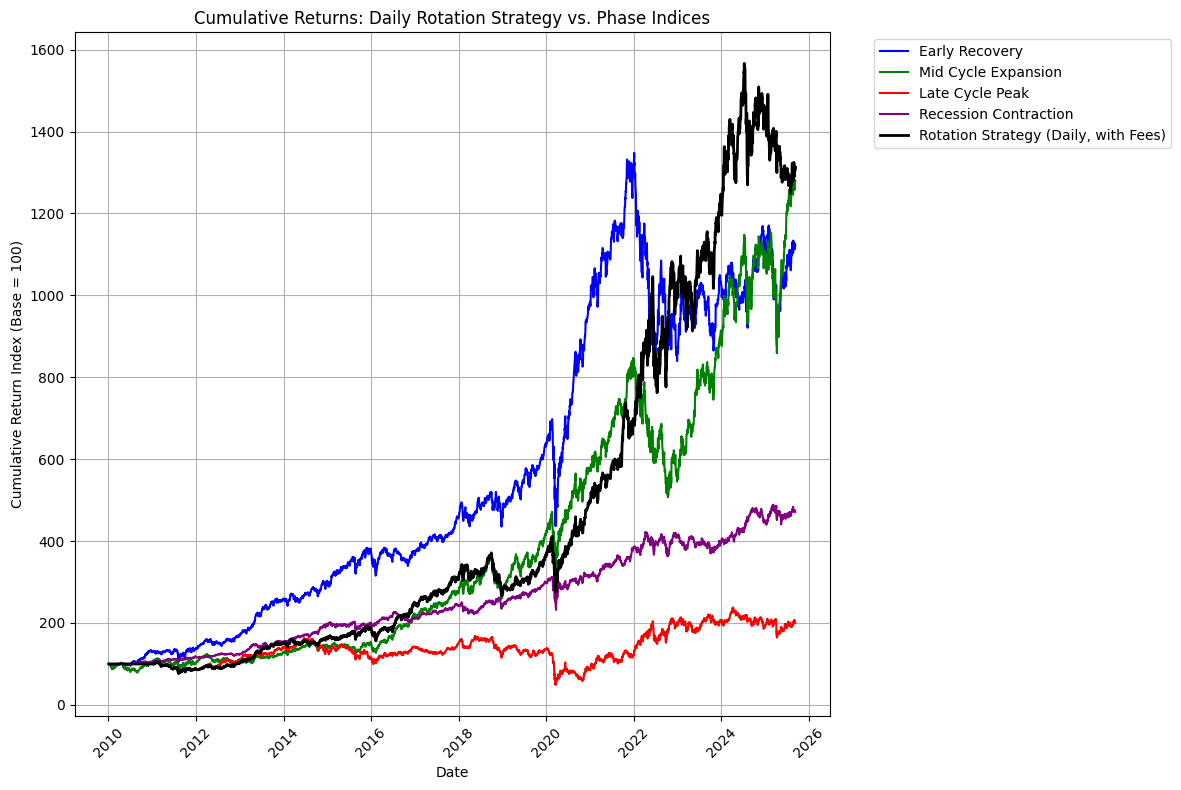

In [6]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define sectors and their representative stocks
sectors = {
    'Technology': ['AAPL', 'MSFT', 'GOOGL', 'NVDA', 'AMD', 'INTC', 'CSCO', 'ORCL', 'QCOM', 'IBM'],
    'Financials': ['JPM', 'BAC', 'WFC', 'GS', 'MS', 'C', 'BLK', 'SCHW', 'AXP', 'USB'],
    'Healthcare': ['JNJ', 'PFE', 'MRK', 'GILD', 'BMY', 'ABBV', 'AMGN', 'LLY', 'CVS', 'UNH'],
    'Consumer_Discretionary': ['AMZN', 'TSLA', 'HD', 'NKE', 'MCD', 'SBUX', 'TGT', 'LOW', 'DIS', 'F'],
    'Energy': ['XOM', 'CVX', 'BP', 'SLB', 'KMI', 'COP', 'OXY', 'VLO', 'PSX', 'HAL'],
    'Industrials': ['CAT', 'GE', 'MMM', 'BA', 'HON', 'UNP', 'RTX', 'DE', 'LMT', 'UPS'],
    'Consumer_Staples': ['PG', 'KO', 'PEP', 'WMT', 'CL', 'COST', 'MO', 'KMB', 'GIS', 'KR'],
    'Utilities': ['DUK', 'SO', 'NEE', 'AEP', 'EXC', 'D', 'ED', 'PEG', 'XEL', 'SRE'],
    'Materials': ['PPG', 'DD', 'NEM', 'FCX', 'LYB', 'ECL', 'APD', 'SHW', 'VMC', 'MLM']
}

# Define economic cycle phases and associated sectors
economic_phases = {
    'Early_Recovery': ['Consumer_Discretionary'],
    'Mid_Cycle_Expansion': ['Technology'],
    'Late_Cycle_Peak': ['Energy'],
    'Recession_Contraction': ['Healthcare', 'Consumer_Staples', 'Utilities']
}

# Define the time period for data and transaction fee
end_date = datetime.now()
start_date = "2010-01-01"
transaction_fee = 0.001  # 0.1% fee in log return terms
window = 252  # Rolling window for ranking (e.g., 252 trading days ~ 1 year)

# Fetch stock data from yfinance
def fetch_stock_data(tickers, start_date, end_date):
    data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
    return data

# Calculate equal-weighted sector index daily log returns
def calculate_sector_index_returns(data, sector_name):
    log_returns = np.log(data / data.shift(1)).dropna()
    weights = [1/len(data.columns)] * len(data.columns)
    index_log_returns = (log_returns * weights).sum(axis=1)
    return index_log_returns

# Calculate phase index daily log returns
def calculate_phase_index_returns(sector_indices, phase_sectors, phase_name):
    phase_data = pd.DataFrame({sector: sector_indices[sector] for sector in phase_sectors})
    weights = [1/len(phase_sectors)] * len(phase_sectors)
    phase_log_returns = (phase_data * weights).sum(axis=1)
    return phase_log_returns

# Calculate cumulative returns for phase indices
def calculate_phase_index_cumulative(phase_returns):
    phase_cumulative = {}
    for phase, returns in phase_returns.items():
        phase_cumulative[phase] = np.exp(returns.cumsum()) * 100
    return phase_cumulative

# Calculate strategy cumulative returns with transaction fees
def calculate_strategy_cumulative(phase_returns):
    returns_df = pd.DataFrame(phase_returns)
    # Calculate rolling means using only past data (shift(1) to exclude current day)
    rolling_means = returns_df.shift(1).rolling(window=window, min_periods=window).mean()
    # Drop rows where all means are NaN
    rolling_means = rolling_means.dropna(how='all')
    # Rank phases (1 = highest mean return)
    ranks = rolling_means.rank(axis=1, method='min', ascending=False)
    top_phase = ranks.idxmin(axis=1)

    # Initialize strategy returns
    strategy_returns = pd.Series(0.0, index=returns_df.index)
    prev_phase = None
    for date in returns_df.index:
        if date in top_phase.index and not pd.isna(top_phase[date]):
            current_phase = top_phase[date]
            # Apply returns for the current phase
            strategy_returns.loc[date] = returns_df.loc[date, current_phase]
            # Apply transaction fee if phase changes
            if prev_phase is not None and current_phase != prev_phase:
                strategy_returns.loc[date] -= transaction_fee
            prev_phase = current_phase
    strategy_cumulative = np.exp(strategy_returns.cumsum()) * 100
    return strategy_returns, strategy_cumulative

# Calculate Sharpe Ratio, Beta, Annualized Return, and Maximum Drawdown
def calculate_metrics(phase_returns, strategy_returns, spy_returns):
    metrics = {}
    annualization_factor = 252
    for phase, returns in phase_returns.items():
        # Sharpe Ratio (using arithmetic mean)
        mean_return = returns.mean() * annualization_factor
        std_return = returns.std() * np.sqrt(annualization_factor)
        sharpe_ratio = mean_return / std_return if std_return != 0 else np.nan

        # Beta
        aligned = pd.concat([returns, spy_returns], axis=1).dropna()
        phase_r = aligned.iloc[:, 0]
        spy_r = aligned.iloc[:, 1]
        beta = phase_r.cov(spy_r) / spy_r.var() if spy_r.var() != 0 else np.nan

        # Annualized Return (geometric, CAGR)
        total_log_return = returns.sum()
        total_return = np.exp(total_log_return) - 1
        years = len(returns) / annualization_factor
        annualized_return = (1 + total_return) ** (1 / years) - 1 if years > 0 else np.nan

        # Max Drawdown
        cumulative_returns = np.exp(returns.cumsum()) * 100
        running_max = cumulative_returns.cummax()
        drawdown = (running_max - cumulative_returns) / running_max
        max_dd = drawdown.max()

        metrics[phase] = {
            'Sharpe Ratio': sharpe_ratio,
            'Beta': beta,
            'Annualized Return (%)': annualized_return * 100,
            'Max Drawdown (%)': max_dd * 100
        }
        print(f"{phase.replace('_', ' ')}: Sharpe Ratio = {sharpe_ratio:.4f}, Beta = {beta:.4f}, Annualized Return = {annualized_return*100:.2f}%, Max Drawdown = {max_dd*100:.2f}%")

    # For Strategy
    mean_return = strategy_returns.mean() * annualization_factor
    std_return = strategy_returns.std() * np.sqrt(annualization_factor)
    sharpe_ratio = mean_return / std_return if std_return != 0 else np.nan

    aligned = pd.concat([strategy_returns, spy_returns], axis=1).dropna()
    strat_r = aligned.iloc[:, 0]
    spy_r = aligned.iloc[:, 1]
    beta = strat_r.cov(spy_r) / spy_r.var() if spy_r.var() != 0 else np.nan

    total_log_return = strategy_returns.sum()
    total_return = np.exp(total_log_return) - 1
    years = len(strategy_returns) / annualization_factor
    annualized_return = (1 + total_return) ** (1 / years) - 1 if years > 0 else np.nan

    cumulative_returns = np.exp(strategy_returns.cumsum()) * 100
    running_max = cumulative_returns.cummax()
    drawdown = (running_max - cumulative_returns) / running_max
    max_dd = drawdown.max()

    metrics['Strategy'] = {
        'Sharpe Ratio': sharpe_ratio,
        'Beta': beta,
        'Annualized Return (%)': annualized_return * 100,
        'Max Drawdown (%)': max_dd * 100
    }
    print(f"Rotation Strategy (Daily, with Fees): Sharpe Ratio = {sharpe_ratio:.4f}, Beta = {beta:.4f}, Annualized Return = {annualized_return*100:.2f}%, Max Drawdown = {max_dd*100:.2f}%")

    return metrics

# Plot cumulative returns
def plot_cumulative_returns(phase_cumulative, strategy_cumulative):
    plt.figure(figsize=(12, 8))
    colors = {
        'Early_Recovery': 'blue',
        'Mid_Cycle_Expansion': 'green',
        'Late_Cycle_Peak': 'red',
        'Recession_Contraction': 'purple'
    }
    for phase, cumulative_data in phase_cumulative.items():
        plt.plot(cumulative_data.index, cumulative_data, label=phase.replace('_', ' '), color=colors[phase])
    plt.plot(strategy_cumulative.index, strategy_cumulative, label='Rotation Strategy (Daily, with Fees)', color='black', linewidth=2)
    plt.title('Cumulative Returns: Daily Rotation Strategy vs. Phase Indices')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Return Index (Base = 100)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Main execution
if __name__ == "__main__":
    sector_indices = {}
    for sector, tickers in sectors.items():
        stock_data = fetch_stock_data(tickers, start_date, end_date)
        sector_indices[sector] = calculate_sector_index_returns(stock_data, sector)

    # Fetch SPY data for benchmark
    spy_data = fetch_stock_data(['SPY'], start_date, end_date)
    spy_returns = np.log(spy_data / spy_data.shift(1)).dropna().squeeze()  # Single column, so squeeze to Series

    phase_returns = {}
    for phase, phase_sectors in economic_phases.items():
        phase_returns[phase] = calculate_phase_index_returns(sector_indices, phase_sectors, phase)

    phase_cumulative = calculate_phase_index_cumulative(phase_returns)
    strategy_returns, strategy_cumulative = calculate_strategy_cumulative(phase_returns)
    metrics = calculate_metrics(phase_returns, strategy_returns, spy_returns)
    plot_cumulative_returns(phase_cumulative, strategy_cumulative)